# Graph regularization

scPoli's prototypes act globally: they align cell types across samples. The graph Laplacian
loss from scANCVI acts locally: it keeps cells that are neighbours *within a sample* close
in the latent space, so the integrated embedding retains each sample's own neighbourhood
structure:

$$L_\text{graph} = \frac{1}{|G|}\sum_{g} \frac{1}{2}\,
\frac{\sum_{(i,j)\in E_g} w_{ij}\lVert z_i - z_j\rVert^2}{\sum_{(i,j)\in E_g} w_{ij}}$$

where $E_g$ are the edges of the kNN graph of sample $g$, built from its own expression
data. Edges never connect different samples.

This tutorial compares three models on the pancreas reference: no graph, graph loss from
scratch, and graph loss added by fine-tuning a trained model. It then trains a query model
with a graph.

In [1]:
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scvi
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

from scpolivi import SCPOLI
from scpolivi.graph import construct_sample_graphs

warnings.filterwarnings("ignore")
scvi.settings.verbosity = logging.WARNING
sc.set_figure_params(figsize=(4.5, 4.5), frameon=False, dpi=80)

In [2]:
adata = sc.read("data/pancreas_sparse.h5ad")
reference = adata[~adata.obs.study.isin(["celseq", "celseq2"])].copy()
query = adata[adata.obs.study.isin(["celseq", "celseq2"])].copy()

## Per-sample graphs

`construct_sample_graphs` builds a kNN graph for each sample on a PCA of that sample's own
highly variable genes. It returns `{sample: adjacency}`. This file holds log-normalized
values, hence `hvg_flavor="seurat"`; use `"seurat_v3"` with raw counts. Graphs from elsewhere
work too, as do scANCVI's `construct_batch_adjacency_matrices` output, an
`(n_obs, n_obs)` matrix or an `adata.obsp` key.

In [3]:
graphs = construct_sample_graphs(reference, "study", recompute_hvg_pca=True, n_hvg=2000,
                                 n_neighbors=15, hvg_flavor="seurat")
pd.DataFrame({s: {"cells": g.shape[0], "edges": g.nnz} for s, g in graphs.items()}).T

,cells,edges
fluidigmc1,638,13384
inDrop1,1937,40466
inDrop2,1724,36252
inDrop3,3605,76004
inDrop4,1303,27070
smarter,1492,33216
smartseq2,2394,47780


To measure neighbourhood preservation, we compute the share of each cell's graph neighbours
that are also among its 15 nearest latent neighbours within the same study.

In [4]:
def neighbourhood_overlap(z, k=15):
    scores = []
    for s, g in graphs.items():
        idx = np.flatnonzero(reference.obs.study == s)
        lat = NearestNeighbors(n_neighbors=k + 1).fit(z[idx]).kneighbors(return_distance=False)[:, 1:]
        for i in range(len(idx)):
            nb = g.indices[g.indptr[i]:g.indptr[i + 1]]
            if len(nb):
                scores.append(len(set(nb) & set(lat[i])) / len(nb))
    return float(np.mean(scores))


def evaluate(model):
    z = model.get_latent(mean=True)
    return {
        "neighbourhood overlap": neighbourhood_overlap(z),
        "cell-type silhouette": (silhouette_score(z, reference.obs.cell_type, sample_size=4000, random_state=0) + 1) / 2,
    }


def new_model():
    a = reference.copy()
    SCPOLI.setup_anndata(a, condition_keys="study", cell_type_keys="cell_type")
    scvi.settings.seed = 0
    return SCPOLI(a, embedding_dims=5)

## Baseline: no graph

In [5]:
baseline = new_model()
baseline.train(n_epochs=50, pretraining_epochs=40, eta=5)
results = {"no graph": evaluate(baseline)}

Epoch 50/50: 100%|██████████| 50/50 [01:43<00:00,  2.07s/it, v_num=1, train_loss=1.04e+3]


## Option A: graph loss from scratch

Attach the graph with `set_graph` and set `graph_weight`. Pretraining is unchanged. From
epoch `pretraining_epochs` on, the loss is ELBO + `eta` × prototype loss + `graph_weight` ×
graph loss.

By default (`graph_sampling="neighbors"`), every cell in a minibatch brings one sampled graph
neighbour, so each cell receives a graph term at every step. scANCVI's estimator
(`graph_sampling="batch"`) only sees edges whose two cells land in the same random minibatch,
which is rare with scPoli's batch size of 128.

In [6]:
scratch = new_model()
scratch.set_graph(graphs, graph_key="study")
scratch.train(n_epochs=50, pretraining_epochs=40, eta=5, graph_weight=10)
results["graph from scratch"] = evaluate(scratch)

Epoch 50/50: 100%|██████████| 50/50 [03:30<00:00,  4.21s/it, v_num=1, train_loss=1.04e+3]


The graph loss is logged like the other losses. It is zero during pretraining:

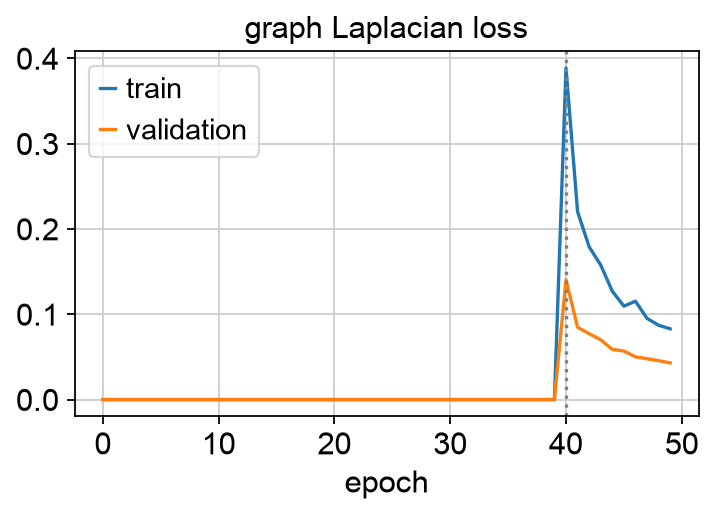

In [7]:
h = scratch.history
plt.figure(figsize=(5, 3))
plt.plot(h["graph_loss_train"], label="train")
plt.plot(h["graph_loss_validation"], label="validation")
plt.axvline(40, color="grey", ls=":")
plt.xlabel("epoch")
plt.title("graph Laplacian loss")
plt.legend();

## Option B: fine-tuning a trained model

`fine_tune` continues training an already trained model with the graph loss. There is no
pretraining phase and no KL warm-up, the prototypes are kept, and the learning rate is
lowered (default 1e-4).

In [8]:
finetuned = baseline   # the trained baseline continues training (in place)
finetuned.set_graph(graphs, graph_key="study")
finetuned.fine_tune(n_epochs=10, graph_weight=10, eta=5)
results["fine-tuned with graph"] = evaluate(finetuned)

Epoch 10/10: 100%|██████████| 10/10 [00:42<00:00,  4.21s/it, v_num=1, train_loss=1.05e+3]


## Comparison

In [9]:
pd.DataFrame(results).T.round(4)

,neighbourhood overlap,cell-type silhouette
no graph,0.1603,0.8586
graph from scratch,0.1699,0.8606
fine-tuned with graph,0.1697,0.8461


Both ways of adding the graph loss raise the share of preserved within-study neighbours, by a
similar amount. Cell-type separation is about unchanged when the graph loss is trained from
scratch, and somewhat lower after fine-tuning. In the 3-seed benchmark (see *Benchmarks*),
training from scratch with weight 10 did not change label transfer or study mixing. Higher
weights strengthen the effect but start to cost batch mixing. Pancreas has little
within-study substructure, so the gains are modest. The term is meant for data with richer
local structure, such as continuous differentiation or cell states.

**Cost.** With `graph_sampling="neighbors"`, each minibatch carries one neighbour per cell, so
epochs with the graph loss take about twice as long (compare the progress bars above).

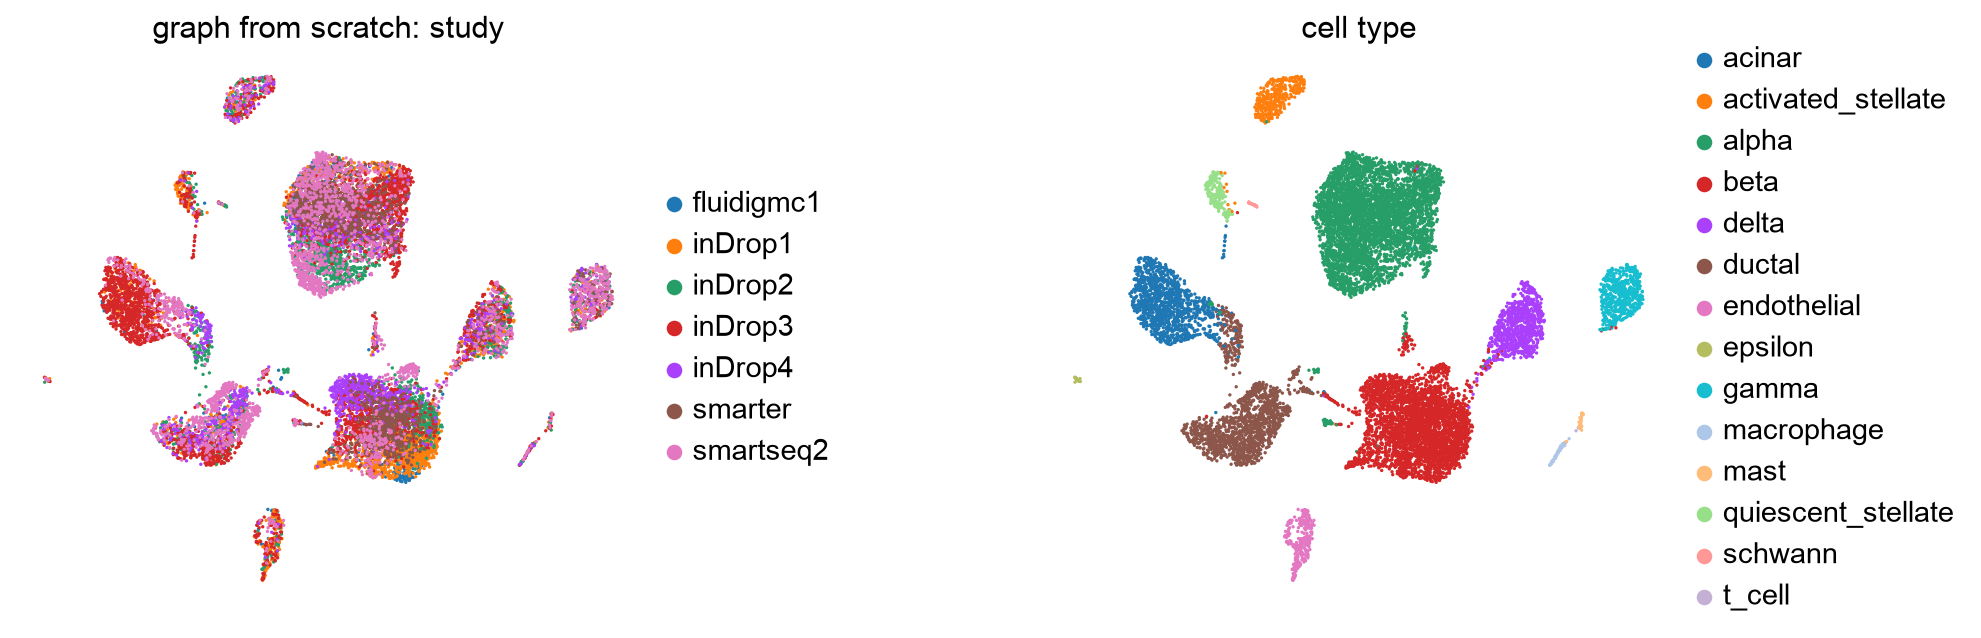

In [10]:
reference.obsm["X_graph"] = scratch.get_latent(mean=True)
sc.pp.neighbors(reference, use_rep="X_graph")
sc.tl.umap(reference)
sc.pl.umap(reference, color=["study", "cell_type"], wspace=0.5, title=["graph from scratch: study", "cell type"])

## A query with its own graph

Query models accept a graph of the query cells. With the default `freeze=True`, only the
query's condition embeddings are trained, so the graph can only act through them.

In [11]:
query_model = SCPOLI.load_query_data(query, reference_model=scratch, labeled_indices=[])
query_graphs = construct_sample_graphs(query_model.adata, "study", recompute_hvg_pca=True, hvg_flavor="seurat")
query_model.set_graph(query_graphs, graph_key="study")
query_model.train(n_epochs=50, pretraining_epochs=40, eta=10, graph_weight=10)
pred = query_model.classify(query, use_mean=True)["cell_type"]["preds"]
known = (query.obs.cell_type != "alpha").to_numpy()
print("query label transfer:", round(float((pred[known] == query.obs.cell_type.values[known]).mean()), 3))

Epoch 50/50: 100%|██████████| 50/50 [00:49<00:00,  1.02it/s, v_num=1, train_loss=1.47e+3]


query label transfer: 0.968


The graph refers to the rows of the model's AnnData and is not saved with the model. Call
`set_graph` again after `SCPOLI.load`.